# Notebook 01 — Problem Definition & Data Understanding

**Đồ án:** Dự đoán thời gian sử dụng còn lại (Remaining Useful Life — RUL) của động cơ turbofan
**Bộ dữ liệu:** NASA C-MAPSS, tập con FD001
**Vị trí trong Industrial AI lifecycle 8 bước:**

| Bước | Tên bước | Notebook / thành phần |
|---|---|---|
| **1** | **Problem Definition** | **Notebook này (Phần A)** |
| **2** | **Data Understanding** | **Notebook này (Phần B, C)** |
| 3 | Data Preparation | `02_data_preparation.ipynb` |
| 4 | Method Selection | `03_method_selection_and_modeling.ipynb` |
| 5 | Model Development | `03_method_selection_and_modeling.ipynb` |
| 6 | Evaluation | `04_evaluation.ipynb` |
| 7 | Deployment | `app/` (web app: trang Tổng quan, Động cơ, Dữ liệu mới) |
| 8 | Monitoring and Improvement | `app/` (web app: trang Mô hình) |

> Nguyên tắc của môn học: **Problem first** — xác định bài toán công nghiệp trước, rồi mới chọn thuật toán.

In [1]:
import os, sys

REPO_URL = "https://github.com/duyenphung206-sudo/turbofan-rul-prediction.git"
REPO_NAME = "turbofan-rul-prediction"

# Dua thu muc lam viec ve goc du an: VS Code mo tu notebooks/, Colab tai du an tu GitHub
if not os.path.exists("src"):
    if os.path.exists("../src"):
        os.chdir("..")
    else:
        if not os.path.exists(REPO_NAME):
            os.system(f"git clone -q {REPO_URL}")
        os.chdir(REPO_NAME)
        os.system("pip install -q scikit-learn==1.9.1")   # trung phien ban luc luu mo hinh
sys.path.append(os.getcwd())
print("Thu muc lam viec:", os.getcwd())

Thu muc lam viec: /tmp/chkrepo


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.rul_utils import (
    load_cmapss, load_rul, add_train_rul, SENSOR_COLS, SETTING_COLS, SENSOR_INFO,
    RUL_CAP, SEQ_LEN, set_plot_style, save_fig, add_panel_labels, BLUE, MUTED, INK,
)

set_plot_style()
pd.set_option("display.max_columns", 30)
ENGINE_COLORS = ["#2a78d6", "#e07b39", "#3a9e5c", "#8e5bc4"]     # mau co dinh cho 4 dong co minh hoa

## Phần A. Bước 1: Problem Definition

### A.1. Sáu thành phần của bài toán công nghiệp

| Thành phần | Nội dung |
|---|---|
| **Vấn đề thực tế** | Động cơ turbofan xuống cấp dần theo số chuyến bay. Nếu hỏng ngoài kế hoạch → máy bay phải dừng khai thác đột xuất, chi phí sửa chữa cao và ảnh hưởng an toàn. Nếu thay thế quá sớm theo lịch cố định → lãng phí phần tuổi thọ còn dùng được. |
| **Nguyên nhân / khó khăn** | (1) Mức xuống cấp bên trong động cơ không quan sát trực tiếp được, chỉ thấy gián tiếp qua cảm biến; (2) mỗi động cơ có mức mòn ban đầu khác nhau nên tuổi thọ rất khác nhau (128–362 chu kỳ trong FD001); (3) tín hiệu cảm biến có nhiễu; (4) dữ liệu hỏng hóc thực tế hiếm. |
| **Mục tiêu** | Ước lượng RUL (số chu kỳ vận hành còn lại trước khi hỏng) của từng động cơ từ dữ liệu cảm biến, đủ sớm và đủ chính xác để lập kế hoạch bảo trì. |
| **Đối tượng sử dụng** | Kỹ sư bảo trì / bộ phận lập kế hoạch bảo trì (maintenance planner) của đơn vị khai thác đội động cơ. |
| **Quyết định cần hỗ trợ** | *Khi nào* đưa động cơ nào vào bảo trì: tiếp tục vận hành — lên kế hoạch — bảo trì ngay. |
| **Ràng buộc** | An toàn: dự đoán **muộn** (báo còn nhiều hơn thực tế) nguy hiểm hơn dự đoán sớm; phải chạy được trên máy tính cá nhân (CPU); kết quả phải giải thích được cho kỹ sư; con người là người quyết định cuối cùng; chỉ dùng thông tin có tại thời điểm dự đoán (không data leakage). |

### A.2. Phát biểu bài toán (theo mẫu trong bài giảng)

> *We want to **[objective]** for **[industrial object]** using **[available information]** so that **[user]** can make **[decision/action]**.*

**Dự đoán số chu kỳ vận hành còn lại (RUL) của từng động cơ turbofan, dựa trên dữ liệu 21 cảm biến và 3 thông số vận hành ghi nhận sau mỗi chu kỳ, để kỹ sư bảo trì quyết định thời điểm đưa động cơ vào bảo trì trước khi xảy ra hỏng hóc ngoài kế hoạch.**

### A.3. Từ bài toán công nghiệp đến hành động

```
Industrial Problem : Động cơ hỏng ngoài kế hoạch / thay thế quá sớm
        ↓
AI Task            : RUL Prediction (hồi quy trên chuỗi thời gian đa biến)
        ↓
AI Output          : RUL dự đoán (chu kỳ) + trạng thái HEALTHY / WARNING / CRITICAL
        ↓
Operational Decision: Tiếp tục vận hành / Lên kế hoạch bảo trì / Bảo trì ngay
        ↓
Industrial Action  : Đặt phụ tùng, xếp lịch dừng máy, thực hiện bảo trì có kế hoạch
```

### A.4. KPI và tiêu chí chấp nhận (đặt ra **trước** khi đánh giá)

Bài giảng 03 yêu cầu: *"Acceptance criteria should be defined before final evaluation"*. Tiêu chí được chia theo 3 mức:

| Mức | Tiêu chí | Ngưỡng chấp nhận | Lý do |
|---|---|---|---|
| Technical (model) | RMSE trên tập test | ≤ 20 chu kỳ **và** tốt hơn baseline dự đoán giá trị trung bình | 20 chu kỳ ≈ 10% tuổi thọ trung bình (206 chu kỳ) |
| Operational (system) | Recall của cảnh báo "RUL ≤ 30" | ≥ 80% | Bỏ sót cảnh báo = nguy cơ hỏng ngoài kế hoạch |
| Operational (system) | Tỉ lệ báo động giả (false alarm rate) | ≤ 10% | Báo động giả gây bảo trì không cần thiết, mất niềm tin |
| Operational (system) | Latency 1 lần dự đoán trên CPU | < 1 giây | Dữ liệu đến theo từng chu kỳ bay nên không cần real-time mili-giây |
| Industrial | Số sự cố ngoài kế hoạch trong mô phỏng | 0 | Mục tiêu chính của predictive maintenance |
| Industrial | Chi phí bảo trì / 1.000 chu kỳ vận hành | Thấp hơn chiến lược bảo trì định kỳ (preventive) | Chứng minh giá trị so với cách làm hiện tại |

## Phần B. Bước 2: Data Understanding

Quy trình khám phá dữ liệu theo bài giảng 02:
**Load Data → Inspect Structure → Check Data Types → Analyze Missing Values → Check Duplicates → Descriptive Statistics → Examine Target/Events → Visualize Patterns → Interpret Industrial Meaning**

### B.1. Nguồn dữ liệu

- **Tên:** Turbofan Engine Degradation Simulation Data Set (C-MAPSS) — NASA Ames Prognostics Center of Excellence.
- **Nguồn chính thức:** NASA Prognostics Data Repository — https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
- **Trích dẫn dữ liệu:** A. Saxena and K. Goebel (2008). "Turbofan Engine Degradation Simulation Data Set", NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.
- **Bài báo mô tả cách sinh dữ liệu:** A. Saxena, K. Goebel, D. Simon, N. Eklund, "Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation," PHM 2008.
- **Phạm vi đồ án:** tập con **FD001** — 1 điều kiện vận hành (Sea Level), 1 dạng hỏng (xuống cấp máy nén cao áp HPC).

Mỗi file là văn bản 26 cột, không có dòng tiêu đề: `unit`, `cycle`, 3 `setting`, 21 `sensor`.

In [3]:
# B.2. Doc du lieu
train = load_cmapss("data/raw/train_FD001.txt")   # chay den khi hong (run-to-failure)
test = load_cmapss("data/raw/test_FD001.txt")     # dung truoc khi hong
rul_test = load_rul("data/raw/RUL_FD001.txt")     # RUL that tai chu ky cuoi cua tung dong co test

print("train:", train.shape, "| test:", test.shape, "| RUL test:", rul_test.shape)
train.head()

train: (20631, 26) | test: (13096, 26) | RUL test: (100, 2)


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### B.3. Cấu trúc dữ liệu — 4 chiều Entity / Time / Measurement / Event

| Chiều | Trong C-MAPSS | Ý nghĩa |
|---|---|---|
| **Entity** | `unit` | Mỗi `unit` là một động cơ trong đội động cơ cùng loại |
| **Time** | `cycle` | Chu kỳ vận hành (≈ 1 chuyến bay); **không có timestamp thật** |
| **Measurement** | `s_1` … `s_21`, `setting_1..3` | 21 cảm biến + 3 thông số vận hành |
| **Event** | chu kỳ cuối của mỗi động cơ trong tập train | Thời điểm hỏng (failure). Tập test dừng trước sự kiện này |

Một dòng dữ liệu = **ảnh chụp (snapshot) của một động cơ sau một chu kỳ vận hành**.

In [4]:
# B.4. Cau truc va kieu du lieu
print("So dong co train:", train["unit"].nunique(), "| So dong co test:", test["unit"].nunique())
print("\nKieu du lieu:")
print(train.dtypes.value_counts())

# Bang mo ta 21 cam bien
sensor_table = pd.DataFrame(
    [(k, v[0], v[1], v[2]) for k, v in SENSOR_INFO.items()],
    columns=["Cot", "Ky hieu", "Y nghia", "Don vi"],
)
sensor_table

So dong co train: 100 | So dong co test: 100

Kieu du lieu:
float64    22
int64       4
Name: count, dtype: int64


,Cot,Ky hieu,Y nghia,Don vi
0,s_1,T2,Nhiệt độ tại cửa vào quạt (fan inlet),°R
1,s_2,T24,Nhiệt độ tại cửa ra LPC,°R
2,s_3,T30,Nhiệt độ tại cửa ra HPC,°R
3,s_4,T50,Nhiệt độ tại cửa ra LPT,°R
4,s_5,P2,Áp suất tại cửa vào quạt,psia
5,s_6,P15,Áp suất tổng trong ống bypass,psia
6,s_7,P30,Áp suất tổng tại cửa ra HPC,psia
7,s_8,Nf,Tốc độ quay vật lý của quạt,rpm
8,s_9,Nc,Tốc độ quay vật lý của lõi,rpm
9,s_10,epr,Tỉ số áp suất động cơ (P50/P2),--


In [5]:
# B.5. Gia tri thieu, dong trung lap, tinh lien tuc cua chu ky
print("So o bi thieu (train):", int(train.isna().sum().sum()))
print("So o bi thieu (test) :", int(test.isna().sum().sum()))
print("So dong trung lap (train):", int(train.duplicated().sum()))

# Kiem tra chu ky co lien tuc khong (1, 2, 3, ... khong bi nhay coc)
gaps = train.groupby("unit")["cycle"].apply(lambda c: (c.diff().dropna() != 1).sum()).sum()
print("So lan chu ky bi gian doan (train):", int(gaps))

So o bi thieu (train): 0
So o bi thieu (test) : 0
So dong trung lap (train): 0
So lan chu ky bi gian doan (train): 0


In [6]:
# B.6. Thong ke mo ta
desc = train[SETTING_COLS + SENSOR_COLS].describe().T[["mean", "std", "min", "max"]]
desc["so_gia_tri_khac_nhau"] = train[SETTING_COLS + SENSOR_COLS].nunique()
desc.round(4)

,mean,std,min,max,so_gia_tri_khac_nhau
setting_1,-0.0000,0.0022,-0.0087,0.0087,158
setting_2,0.0000,0.0003,-0.0006,0.0006,13
setting_3,100.0000,0.0000,100.0000,100.0000,1
s_1,518.6700,0.0000,518.6700,518.6700,1
s_2,642.6809,0.5001,641.2100,644.5300,310
s_3,1590.5231,6.1311,1571.0400,1616.9100,3012
s_4,1408.9338,9.0006,1382.2500,1441.4900,4051
s_5,14.6200,0.0000,14.6200,14.6200,1
s_6,21.6098,0.0014,21.6000,21.6100,2
s_7,553.3677,0.8851,549.8500,556.0600,513


**Nhận xét:**
- `setting_3` và các cảm biến `s_1, s_5, s_10, s_16, s_18, s_19` **chỉ có 1 giá trị** (hằng số); `s_6` chỉ có 2 giá trị (21.60 / 21.61). Các cột này không mang thông tin về sự xuống cấp trong FD001.
- `setting_1`, `setting_2` dao động rất nhỏ quanh 0 → đúng với mô tả FD001: **một** điều kiện vận hành.
- Thang đo các cảm biến rất khác nhau (ví dụ `s_9` ≈ 9000, `s_15` ≈ 8.4) → cần scaling ở Bước 3.

Tuoi tho dong co train (chu ky):
count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64

Do dai chuoi du lieu cua dong co test (chu ky):
count    100.0
mean     131.0
std       53.6
min       31.0
25%       88.8
50%      133.5
75%      164.2
max      303.0
Name: cycle, dtype: float64
So dong co test co <= 100 chu ky: 30 | < 50 chu ky: 7


Da luu hinh: reports/figures/01_engine_life_distribution.png


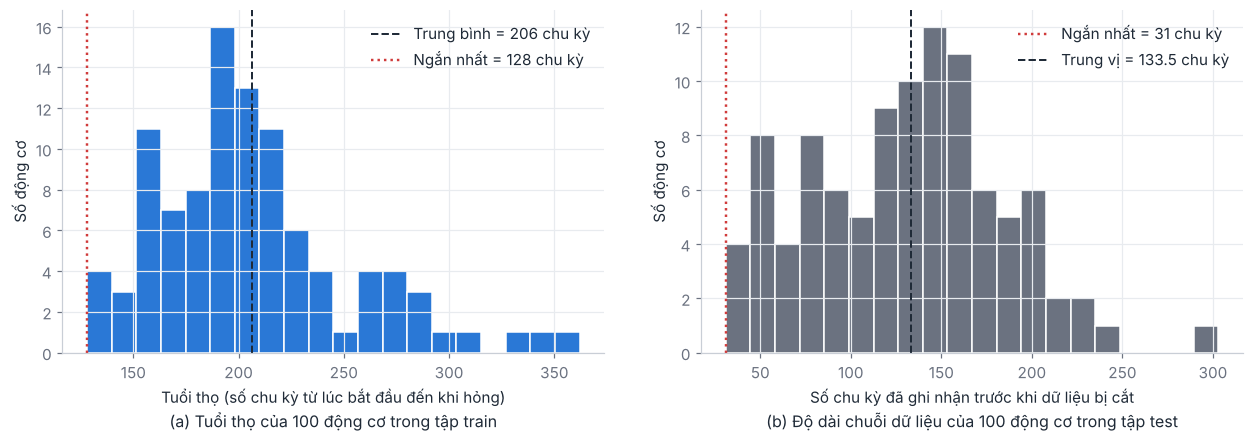

In [7]:
# B.7. Su kien hong: tuoi tho cua tung dong co train va do dai chuoi du lieu cua dong co test
life = train.groupby("unit")["cycle"].max()          # tuoi tho = chu ky cuoi cung (luc hong)
test_len = test.groupby("unit")["cycle"].max()       # so chu ky da ghi nhan truoc khi du lieu test bi cat

print("Tuoi tho dong co train (chu ky):")
print(life.describe().round(1))
print("\nDo dai chuoi du lieu cua dong co test (chu ky):")
print(test_len.describe().round(1))
print("So dong co test co <= 100 chu ky:", int((test_len <= 100).sum()), "| < 50 chu ky:", int((test_len < 50).sum()))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
axes[0].hist(life, bins=20, color=BLUE, edgecolor="white")
axes[0].axvline(life.mean(), color=INK, linestyle="--", linewidth=1.3, label=f"Trung bình = {life.mean():.0f} chu kỳ")
axes[0].axvline(life.min(), color="#d03b3b", linestyle=":", linewidth=1.6, label=f"Ngắn nhất = {life.min()} chu kỳ")
axes[0].set(xlabel="Tuổi thọ (số chu kỳ từ lúc bắt đầu đến khi hỏng)", ylabel="Số động cơ")
axes[0].legend(loc="upper right")

axes[1].hist(test_len, bins=20, color=MUTED, edgecolor="white")
axes[1].axvline(test_len.min(), color="#d03b3b", linestyle=":", linewidth=1.6, label=f"Ngắn nhất = {test_len.min()} chu kỳ")
axes[1].axvline(test_len.median(), color=INK, linestyle="--", linewidth=1.3, label=f"Trung vị = {test_len.median():.1f} chu kỳ")
axes[1].set(xlabel="Số chu kỳ đã ghi nhận trước khi dữ liệu bị cắt", ylabel="Số động cơ")
axes[1].legend(loc="upper right")
fig.tight_layout(w_pad=3)
add_panel_labels(fig, axes, ["(a) Tuổi thọ của 100 động cơ trong tập train",
                             "(b) Độ dài chuỗi dữ liệu của 100 động cơ trong tập test"])
save_fig(fig, "01_engine_life_distribution.png")
plt.show()

**Nhận xét:** tuổi thọ dao động rất rộng (128 → 362 chu kỳ, trung bình ≈ 206). Đây chính là lý do **bảo trì định kỳ theo một mốc cố định không hiệu quả**: đặt mốc thấp thì lãng phí tuổi thọ của động cơ "khỏe", đặt mốc cao thì động cơ "yếu" hỏng trước khi kịp bảo trì.

Da luu hinh: reports/figures/01_sensor_trends_a.png


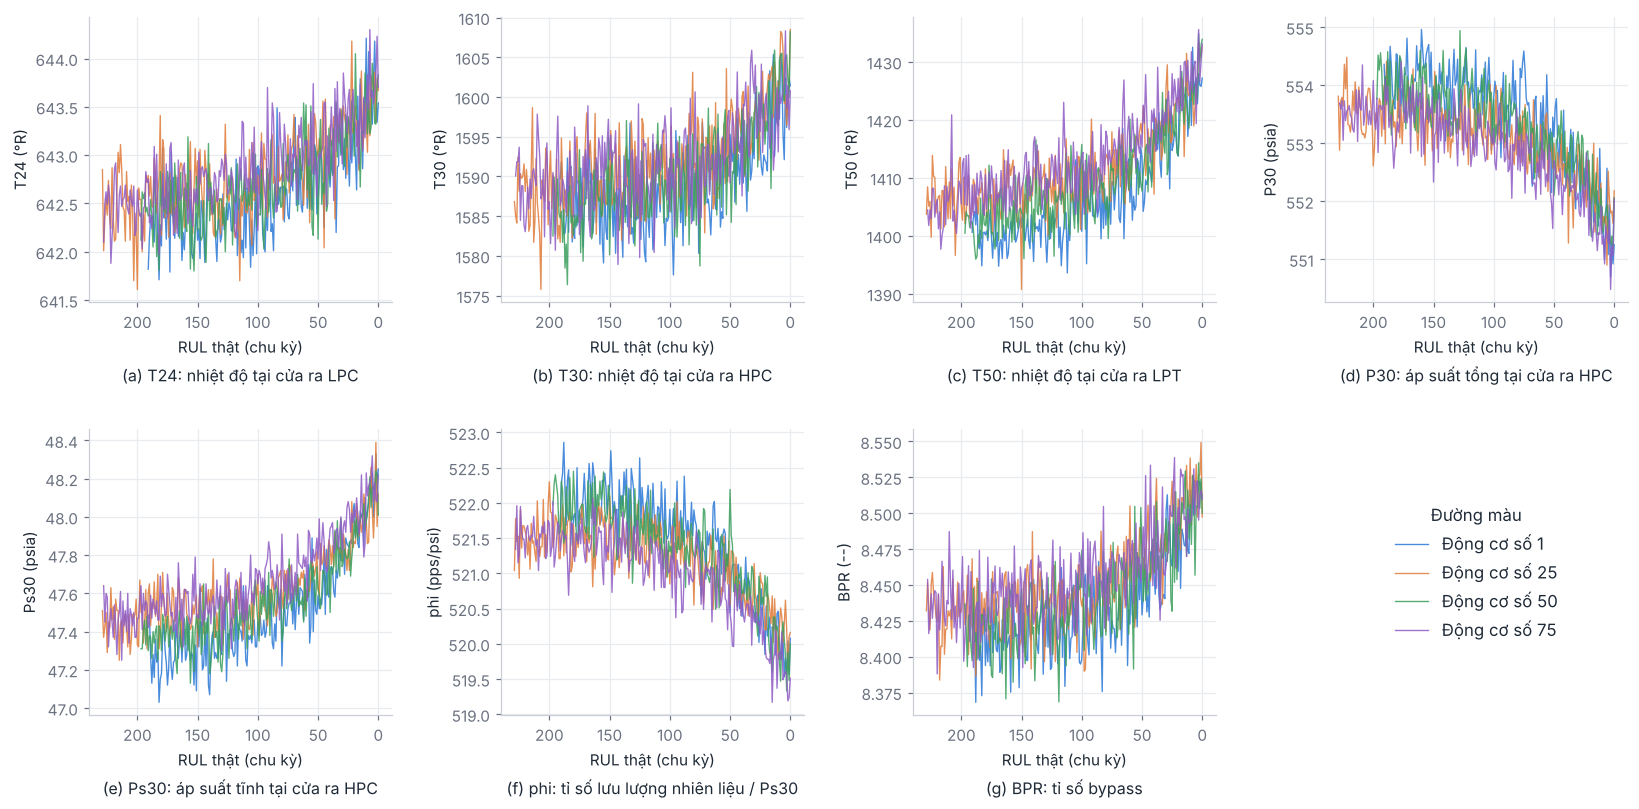

Da luu hinh: reports/figures/01_sensor_trends_b.png


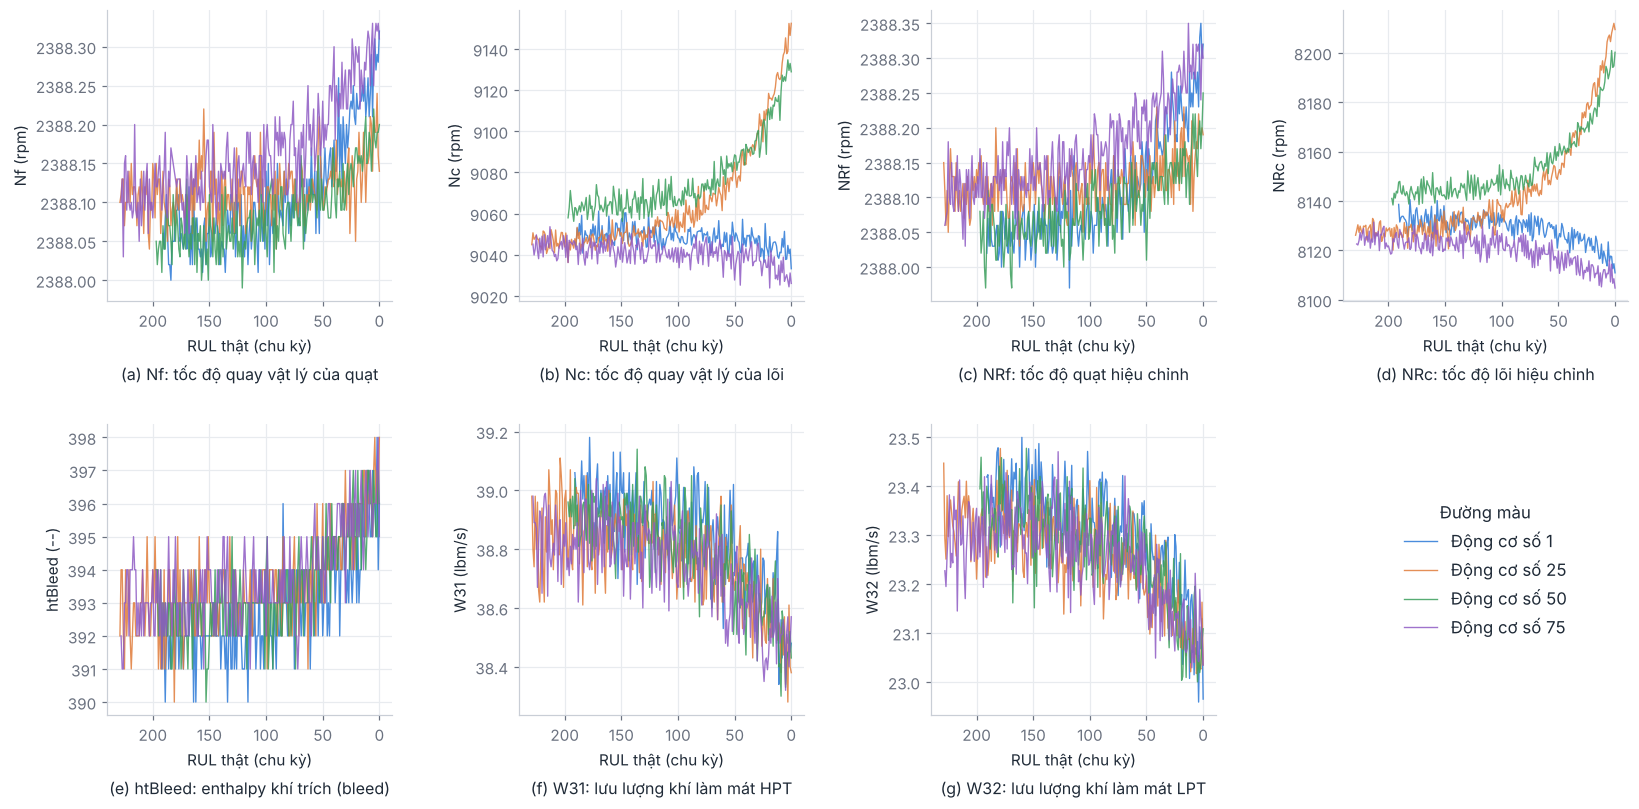

In [8]:
# B.8. Xu huong cam bien khi dong co tien dan toi hong (4 dong co minh hoa, chia 2 nhom cam bien)
train = add_train_rul(train)                 # them cot RUL_raw (chua gioi han) va RUL (gioi han 125)
varying = [s for s in SENSOR_COLS if train[s].nunique() > 2]    # 14 cam bien co bien thien
sample_units = [1, 25, 50, 75]               # 4 dong co minh hoa
SENSOR_GROUPS = {
    "01_sensor_trends_a.png": ["s_2", "s_3", "s_4", "s_7", "s_11", "s_12", "s_15"],     # nhiet do, ap suat, ti so
    "01_sensor_trends_b.png": ["s_8", "s_9", "s_13", "s_14", "s_17", "s_20", "s_21"],   # toc do quay, khi trich, luu luong
}
assert sorted(sum(SENSOR_GROUPS.values(), [])) == sorted(varying)

for file_name, group in SENSOR_GROUPS.items():
    fig, axes = plt.subplots(2, 4, figsize=(15, 7.2))
    axes = axes.ravel()
    for ax, s in zip(axes, group):
        for u, color in zip(sample_units, ENGINE_COLORS):
            g = train[train["unit"] == u]
            ax.plot(g["RUL_raw"], g[s], color=color, linewidth=0.9, alpha=0.85, label=f"Động cơ số {u}")
        ax.invert_xaxis()                    # ben phai la luc hong (RUL = 0)
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.set(xlabel="RUL thật (chu kỳ)", ylabel=f"{SENSOR_INFO[s][0]} ({SENSOR_INFO[s][2]})")
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].axis("off")
    axes[-1].legend(handles, labels, loc="center", title="Đường màu", fontsize=11, title_fontsize=11)
    fig.tight_layout(h_pad=4.5, w_pad=2)
    letters = "abcdefg"
    add_panel_labels(fig, axes[:len(group)],
                     [f"({letters[i]}) {SENSOR_INFO[s][0]}: {SENSOR_INFO[s][1][0].lower() + SENSOR_INFO[s][1][1:]}" for i, s in enumerate(group)])
    save_fig(fig, file_name)
    plt.show()

Da luu hinh: reports/figures/01_sensor_direction.png


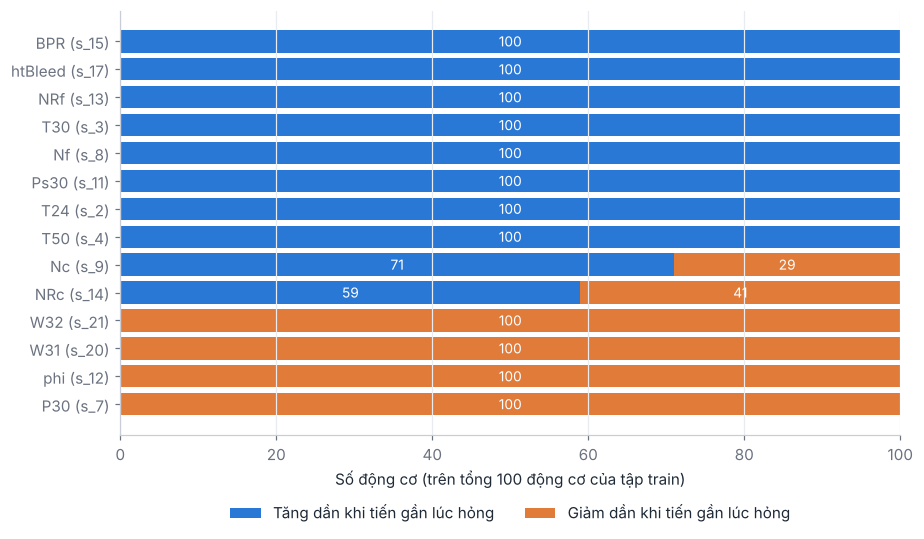

,So_dong_co_tang,So_dong_co_giam
s_13,100,0
s_3,100,0
s_8,100,0
s_11,100,0
s_2,100,0
s_4,100,0
s_17,100,0
s_15,100,0
s_9,71,29
s_14,59,41


In [9]:
# B.8b. Huong thay doi cua tung cam bien trong 100 chu ky cuoi truoc khi hong, tren ca 100 dong co train
# Huong = dau cua he so goc duong thang khop voi 100 chu ky cuoi (> 0: tang dan, < 0: giam dan)
rows = {}
for unit, g in train.groupby("unit"):
    tail = g.tail(100)
    rows[unit] = {s: np.polyfit(tail["cycle"], tail[s], 1)[0] for s in varying}
direction = pd.DataFrame(rows).T
trend_count = pd.DataFrame({"So_dong_co_tang": (direction > 0).sum(), "So_dong_co_giam": (direction < 0).sum()})
trend_count = trend_count.sort_values("So_dong_co_tang")

fig, ax = plt.subplots(figsize=(8.5, 5))
labels = [f"{SENSOR_INFO[s][0]} ({s})" for s in trend_count.index]
b1 = ax.barh(labels, trend_count["So_dong_co_tang"], color=BLUE, label="Tăng dần khi tiến gần lúc hỏng")
b2 = ax.barh(labels, trend_count["So_dong_co_giam"], left=trend_count["So_dong_co_tang"], color="#e07b39", label="Giảm dần khi tiến gần lúc hỏng")
ax.bar_label(b1, labels=[str(v) if v else "" for v in trend_count["So_dong_co_tang"]], label_type="center", color="white", fontsize=9)
ax.bar_label(b2, labels=[str(v) if v else "" for v in trend_count["So_dong_co_giam"]], label_type="center", color="white", fontsize=9)
ax.set(xlabel="Số động cơ (trên tổng 100 động cơ của tập train)", xlim=(0, 100))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "01_sensor_direction.png")
plt.show()
trend_count.sort_values("So_dong_co_tang", ascending=False)

**Nhận xét (ý nghĩa công nghiệp):**
- Khi còn xa lúc hỏng (bên trái), tín hiệu gần như **đi ngang kèm nhiễu** → động cơ khỏe, chưa có dấu hiệu xuống cấp.
- Khoảng 100–130 chu kỳ cuối, nhiều cảm biến bắt đầu **có xu hướng rõ**: nhiệt độ `T24, T30, T50` và `Ps30` tăng; áp suất `P30`, `phi`, lưu lượng khí làm mát `W31, W32` giảm — phù hợp với hiện tượng máy nén cao áp (HPC) mất hiệu suất.
- Nhiễu từng điểm khá lớn so với xu hướng → cần làm mịn (rolling) ở Bước 3.
- Trên cả 100 động cơ train (hình hướng thay đổi): 12/14 cảm biến đổi hướng giống nhau ở mọi động cơ trong 100 chu kỳ cuối (8 cảm biến tăng, 4 cảm biến giảm). Riêng tốc độ lõi `Nc` tăng ở 71 động cơ và giảm ở 29 động cơ, `NRc` tăng ở 59 và giảm ở 41 động cơ, nên hướng thay đổi của hai cảm biến này phụ thuộc từng động cơ.

Da luu hinh: reports/figures/01_correlation_with_rul.png


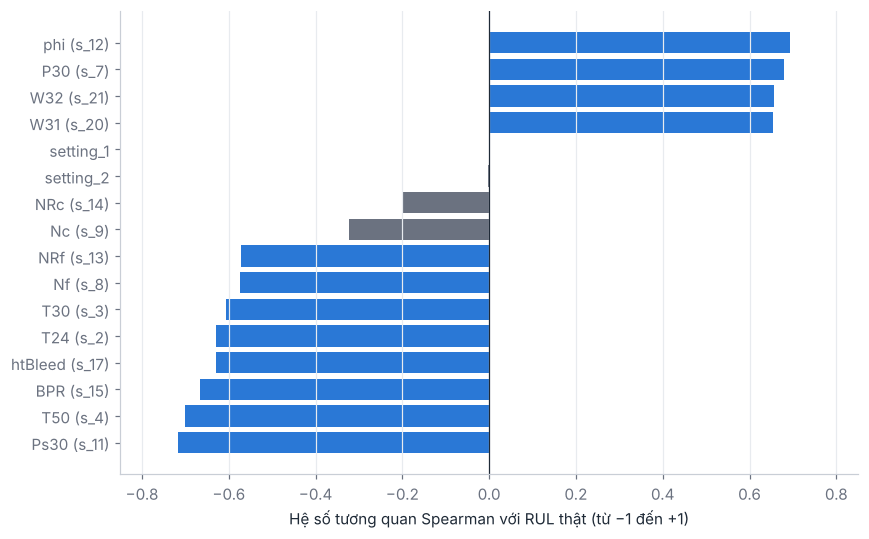

s_11        -0.718
s_4         -0.702
s_15        -0.666
s_17        -0.629
s_2         -0.629
s_3         -0.606
s_8         -0.574
s_13        -0.573
s_9         -0.322
s_14        -0.202
setting_2   -0.004
setting_1   -0.001
s_20         0.653
s_21         0.657
s_7          0.679
s_12         0.693
dtype: float64

In [10]:
# B.9. Tuong quan Spearman giua tung bien va RUL
corr = train[["setting_1", "setting_2"] + varying].corrwith(train["RUL_raw"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f"{SENSOR_INFO[c][0]} ({c})" if c in SENSOR_INFO else c for c in corr.index], corr.values,
        color=[BLUE if abs(v) >= 0.5 else MUTED for v in corr.values])
ax.axvline(0, color=INK, linewidth=0.8)
ax.set(xlabel="Hệ số tương quan Spearman với RUL thật (từ −1 đến +1)", xlim=(-0.85, 0.85))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "01_correlation_with_rul.png")
plt.show()
corr.round(3)

**Nhận xét:** 12/14 cảm biến có tương quan mạnh với RUL (|ρ| ≈ 0.57–0.72); `s_9` (Nc) và `s_14` (NRc) yếu hơn (|ρ| ≈ 0.2–0.3) vì tốc độ lõi biến thiên khác nhau giữa các động cơ, nhưng vẫn mang thông tin nên được giữ lại. `setting_1`, `setting_2` có tương quan ≈ 0 (`setting_3` là hằng số nên không tính) → trong FD001 các thông số vận hành chỉ là bối cảnh cố định, không phản ánh xuống cấp.

## Phần C. Phân tích 3B (Broken / Bad Quality / Background)

Các con số dưới đây được **tính trực tiếp từ dữ liệu** để làm bằng chứng cho bảng 3B.

In [11]:
# Broken: du lieu thieu, trung lap, gian doan
broken = {
    "O du lieu bi thieu (train + test)": int(train[SENSOR_COLS].isna().sum().sum() + test.isna().sum().sum()),
    "Dong trung lap": int(train.duplicated().sum()),
    "Chu ky bi gian doan": int(gaps),
    "Dong co test bi cat truoc khi hong": f"{test['unit'].nunique()}/100",
    "Chuoi test ngan nhat (chu ky)": int(test_len.min()),
}
pd.Series(broken, name="BROKEN").to_frame()

,BROKEN
O du lieu bi thieu (train + test),0
Dong trung lap,0
Chu ky bi gian doan,0
Dong co test bi cat truoc khi hong,100/100
Chuoi test ngan nhat (chu ky),31


In [12]:
# Bad quality: nhieu va gioi han cam bien
# Uoc luong muc nhieu: do lech chuan cua (tin hieu - trung binh truot 10 chu ky) so voi bien do tin hieu
noise = {}
for s in varying:
    smooth = train.groupby("unit")[s].transform(lambda x: x.rolling(10, min_periods=1, center=True).mean())
    noise[s] = (train[s] - smooth).std() / (train[s].max() - train[s].min())
noise = pd.Series(noise).sort_values(ascending=False)

bad_quality = {
    "Cam bien hang so (khong mang thong tin)": ", ".join(s for s in SENSOR_COLS if train[s].nunique() == 1),
    "Cam bien gan nhu hang so (2 gia tri)": ", ".join(s for s in SENSOR_COLS if train[s].nunique() == 2),
    "Cam bien do phan giai thap (<= 60 gia tri khac nhau)": ", ".join(s for s in varying if train[s].nunique() <= 60),
    "Muc nhieu trung binh (% bien do)": f"{noise.mean() * 100:.1f}%",
    "Cam bien nhieu nhat": f"{noise.index[0]} ({noise.iloc[0] * 100:.1f}% bien do)",
}
pd.Series(bad_quality, name="BAD QUALITY").to_frame()

,BAD QUALITY
Cam bien hang so (khong mang thong tin),"s_1, s_5, s_10, s_16, s_18, s_19"
Cam bien gan nhu hang so (2 gia tri),s_6
Cam bien do phan giai thap (<= 60 gia tri khac nhau),"s_8, s_13, s_17"
Muc nhieu trung binh (% bien do),6.0%
Cam bien nhieu nhat,s_2 (8.6% bien do)


Da luu hinh: reports/figures/01_sensor_noise_example.png


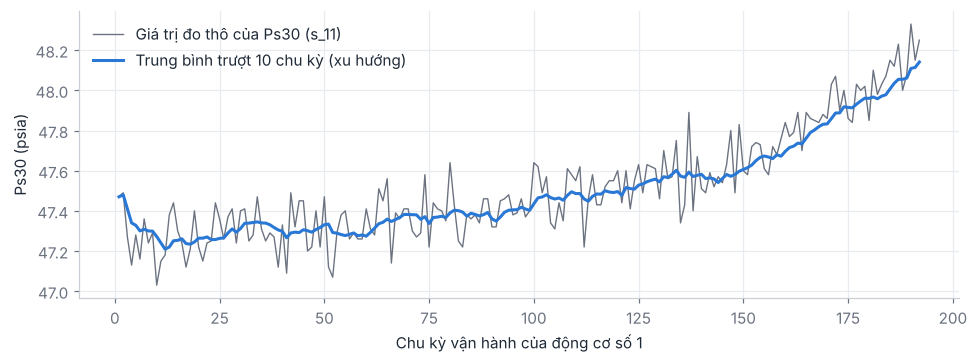

In [13]:
# Minh hoa nhieu: tin hieu tho va duong trung binh truot cua 1 cam bien, 1 dong co
g = train[train["unit"] == 1]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(g["cycle"], g["s_11"], color=MUTED, linewidth=0.9, label="Giá trị đo thô của Ps30 (s_11)")
ax.plot(g["cycle"], g["s_11"].rolling(10, min_periods=1).mean(), color=BLUE, label="Trung bình trượt 10 chu kỳ (xu hướng)")
ax.set(xlabel="Chu kỳ vận hành của động cơ số 1", ylabel="Ps30 (psia)")
ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "01_sensor_noise_example.png")
plt.show()

### Bảng tổng hợp 3B cho C-MAPSS FD001

| 3B | Biểu hiện trong dữ liệu (bằng chứng ở các ô trên) | Ảnh hưởng tới bài toán | Cách xử lý trong đồ án |
|---|---|---|---|
| **Broken** — dữ liệu thiếu, gián đoạn | Không có ô thiếu, không trùng lặp, chu kỳ liên tục (vì là dữ liệu mô phỏng). Nhưng 100/100 động cơ test **bị cắt trước khi hỏng**, chuỗi ngắn nhất chỉ 31 chu kỳ. Dữ liệu thật ngoài nhà máy sẽ có mất kết nối, cảm biến hỏng. | Mô hình cần lịch sử đủ dài mới dự đoán được; dữ liệu thật thiếu có thể làm pipeline dừng. | Pipeline có bước forward-fill theo từng động cơ; kiểm thử robustness bằng cách **cố ý xóa** 10–30% dữ liệu (Notebook 04); app kiểm tra dữ liệu thiếu trước khi dự đoán. |
| **Bad Quality** — nhiễu, sai số, sensor limitation | 7/21 cảm biến hằng số hoặc gần hằng số; 3 cảm biến độ phân giải thấp (`s_8`, `s_13`, `s_17`); nhiễu trung bình ≈ 6% biên độ tín hiệu, che khuất xu hướng ở giai đoạn đầu. | Nhiễu làm dự đoán dao động → báo động giả; cảm biến hằng số là đặc trưng vô ích. | Loại 7 cảm biến hằng số; làm mịn bằng trung bình trượt; kiểm thử robustness bằng cách **cộng thêm nhiễu** (Notebook 04). |
| **Background** — thiếu context vận hành | Không có timestamp thật (chỉ có số chu kỳ); 3 thông số vận hành ẩn danh; không biết mức mòn ban đầu của từng động cơ; không có lịch sử bảo trì; không có nhãn dạng hỏng theo từng động cơ; dữ liệu là **mô phỏng**, không phải đo từ động cơ thật; FD001 chỉ có 1 điều kiện vận hành. | Không thể quy đổi RUL ra ngày/giờ; mô hình chỉ đúng trong điều kiện FD001; không chẩn đoán được nguyên nhân hỏng. | Giới hạn phạm vi rõ ràng (FD001); kiểm thử trên FD002 để **chứng minh** mô hình sai khi điều kiện vận hành đổi (Notebook 04); app cảnh báo khi dữ liệu nằm ngoài vùng đã huấn luyện; ghi rõ ở phần Limitations. |

## Kết luận

**Dữ liệu có sẵn sàng cho bài toán RUL không?** (bài giảng 02: *"Data readiness is problem-dependent"*)

- Có **lịch sử xuống cấp đầy đủ đến lúc hỏng** (run-to-failure) của 100 động cơ → gán được nhãn RUL. Đây là điều kiện bắt buộc cho bài toán RUL.
- Có tập test độc lập với RUL thật do NASA cung cấp → đánh giá khách quan.
- 14/21 cảm biến có xu hướng rõ theo mức xuống cấp.
- Hạn chế: thiếu context vận hành (Background) → kết quả chỉ nên hiểu trong phạm vi FD001 và là dữ liệu mô phỏng.

**Đầu vào cho Bước 3 (Data Preparation):**
1. Loại 7 cảm biến hằng số + 3 thông số vận hành.
2. Scaling vì thang đo khác nhau.
3. Làm mịn nhiễu bằng đặc trưng trượt (rolling).
4. Chia train/validation **theo động cơ** (không chia ngẫu nhiên theo dòng) để tránh information leakage.